# Diabetes Classification Using Decision Trees

**Author:** Cleane Santos  
**Date:** April 2026  
**Objective:** Develop and compare decision tree classifiers with multiple preprocessing strategies for diabetes diagnosis prediction.

---

## Executive Summary

This project analyzes the Pima Indians Diabetes Database to build a predictive model for diabetes diagnosis. The key innovation is the comparison of 8 distinct preprocessing strategies to handle missing data (encoded as zeros), demonstrating the critical impact of data preprocessing on model performance.

**Key Results:**
- **Best Model:** Conditional Median Imputation (Base 6)
- **F1-Score:** 0.591 (primary metric for imbalanced classification)
- **Accuracy:** 77.9% | **AUC-ROC:** 0.753
- **Data Retention:** 100% (no rows discarded)

---

## 1. Setup and Configuration

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from typing import Tuple, Dict
import warnings
warnings.filterwarnings('ignore')

# Machine Learning
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    roc_curve, auc
)
from sklearn.preprocessing import StandardScaler
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from imblearn.over_sampling import SMOTE

# Configuration
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

# Visualization
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10
sns.set_style('whitegrid')
sns.set_palette('husl')

print('✓ Libraries loaded successfully')
print(f'✓ Random state set to {RANDOM_STATE} for reproducibility')

✓ Libraries loaded successfully
✓ Random state set to 42 for reproducibility


## 2. Data Loading and Initial Exploration

In [2]:
# Load data (adjust path as needed for local/Colab)
try:
    from google.colab import drive
    drive.mount('/content/drive')
    file_path = '/content/drive/MyDrive/Portfolio_Cleane/Data_Science/DecisionTree/diabetes.csv'
except:
    file_path = 'diabetes.csv'  # Local path fallback

df = pd.read_csv(file_path)

print(f"Dataset shape: {df.shape}")
print(f"Rows: {df.shape[0]} | Columns: {df.shape[1]}")
print(f"\nFirst 5 rows:")
print(df.head())

Mounted at /content/drive
Dataset shape: (768, 9)
Rows: 768 | Columns: 9

First 5 rows:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  DiabetesPedigreeFunction  Age  Outcome
0            6      148             72             35        0  33.6                     0.627   50        1
1            1       85             66             29        0  26.6                     0.351   31        0
2            8      183             64              0        0  23.3                     0.672   32        1
3            1       89             66             23       94  28.1                     0.167   21        0
4            0      137             40             35      168  43.1                     2.288   33        1


## 3. Data Quality Assessment

In [3]:
# Define columns with physiologically impossible zeros
COLS_ZERO = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
TARGET = 'Outcome'

print("\n" + "="*70)
print("DATA QUALITY REPORT")
print("="*70)

# Missing data analysis
print("\nMissing Values (Coded as Zeros):")
print("-" * 70)
missing_analysis = []
for col in COLS_ZERO:
    count = (df[col] == 0).sum()
    pct = 100 * count / len(df)
    missing_analysis.append({
        'Variable': col,
        'Zero Count': count,
        'Percentage': f"{pct:.1f}%"
    })

missing_df = pd.DataFrame(missing_analysis)
print(missing_df.to_string(index=False))

# Target variable analysis
print(f"\nTarget Variable Distribution:")
print("-" * 70)
outcome_counts = df[TARGET].value_counts().sort_index()
outcome_pcts = df[TARGET].value_counts(normalize=True).sort_index() * 100

for idx, (count, pct) in enumerate(zip(outcome_counts, outcome_pcts)):
    label = "Non-Diabetic" if idx == 0 else "Diabetic"
    print(f"  {idx} ({label}): {count:4d} cases ({pct:5.1f}%)")

print(f"\nClass Imbalance Ratio: {outcome_pcts[1]/outcome_pcts[0]:.2f}:1 (minority:majority)")
print("\n⚠️  Note: Significant class imbalance and missing data require careful handling")


DATA QUALITY REPORT

Missing Values (Coded as Zeros):
----------------------------------------------------------------------
     Variable  Zero Count Percentage
      Glucose           5       0.7%
BloodPressure          35       4.6%
SkinThickness         227      29.6%
      Insulin         374      48.7%
          BMI          11       1.4%

Target Variable Distribution:
----------------------------------------------------------------------
  0 (Non-Diabetic):  500 cases ( 65.1%)
  1 (Diabetic):  268 cases ( 34.9%)

Class Imbalance Ratio: 0.54:1 (minority:majority)

⚠️  Note: Significant class imbalance and missing data require careful handling


## 4. Descriptive Statistics

In [4]:
print("\nSUMMARY STATISTICS")
print("="*70)
print(df.describe().round(2))


SUMMARY STATISTICS
       Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin     BMI  DiabetesPedigreeFunction     Age  Outcome
count       768.00   768.00         768.00         768.00   768.00  768.00                    768.00  768.00   768.00
mean          3.85   120.89          69.11          20.54    79.80   31.99                      0.47   33.24     0.35
std           3.37    31.97          19.36          15.95   115.24    7.88                      0.33   11.76     0.48
min           0.00     0.00           0.00           0.00     0.00    0.00                      0.08   21.00     0.00
25%           1.00    99.00          62.00           0.00     0.00   27.30                      0.24   24.00     0.00
50%           3.00   117.00          72.00          23.00    30.50   32.00                      0.37   29.00     0.00
75%           6.00   140.25          80.00          32.00   127.25   36.60                      0.63   41.00     1.00
max          17.00   199.00         

## 5. Exploratory Data Analysis

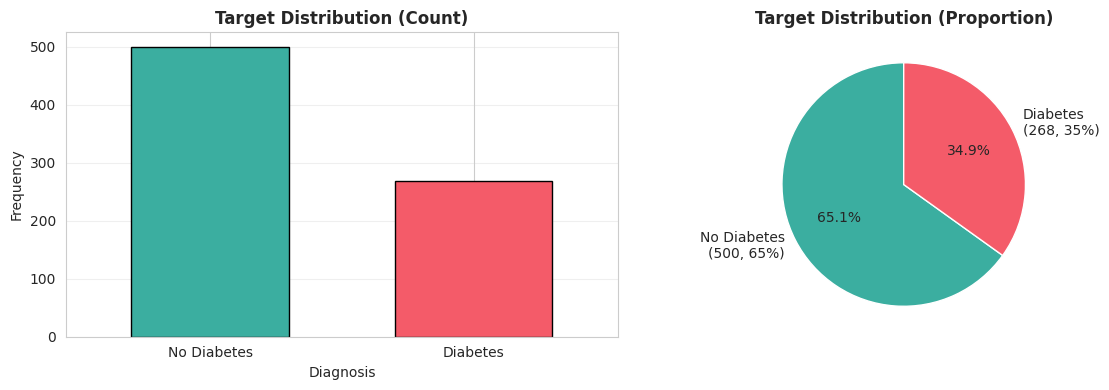

In [5]:
# Target distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Count plot
df[TARGET].value_counts().sort_index().plot(
    kind='bar', ax=axes[0], color=['#3BAEA0', '#F45B69'], edgecolor='black', width=0.6
)
axes[0].set_title('Target Distribution (Count)', fontweight='bold', fontsize=12)
axes[0].set_xlabel('Diagnosis')
axes[0].set_ylabel('Frequency')
axes[0].set_xticklabels(['No Diabetes', 'Diabetes'], rotation=0)
axes[0].grid(axis='y', alpha=0.3)

# Pie chart
sizes = df[TARGET].value_counts()
axes[1].pie(sizes, labels=[f'No Diabetes\n({sizes[0]}, 65%)' , f'Diabetes\n({sizes[1]}, 35%)'],
            colors=['#3BAEA0', '#F45B69'], autopct='%1.1f%%', startangle=90)
axes[1].set_title('Target Distribution (Proportion)', fontweight='bold', fontsize=12)

plt.tight_layout()
plt.show()

In [6]:
# Distribution of features
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

feature_cols = [col for col in df.columns if col != TARGET]

for i, col in enumerate(feature_cols):
    sns.histplot(data=df, x=col, kde=True, ax=axes[i], color='#3BAEA0', edgecolor='black')
    axes[i].set_title(f'{col}', fontweight='bold')
    axes[i].set_ylabel('Frequency')

fig.suptitle('Distribution of Predictor Variables', fontsize=14, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()

<Figure size 1500x1200 with 9 Axes>

In [7]:
# Correlation matrix
corr = df.corr(numeric_only=True)
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='crest', square=True,
            cbar_kws={'label': 'Pearson Correlation'}, linewidths=0.5, vmin=-1, vmax=1)
plt.title('Correlation Matrix - All Variables', fontweight='bold', fontsize=12, pad=15)
plt.tight_layout()
plt.show()

print("\nCorrelation with Outcome (sorted by absolute value):")
print("-" * 50)
outcome_corr = corr[TARGET].drop(TARGET).abs().sort_values(ascending=False)
for var, corr_val in outcome_corr.items():
    actual_corr = corr.loc[var, TARGET]
    print(f"  {var:25s}: {actual_corr:7.4f}")

<Figure size 1000x800 with 2 Axes>


Correlation with Outcome (sorted by absolute value):
--------------------------------------------------
  Glucose                  :  0.4666
  BMI                      :  0.2927
  Age                      :  0.2384
  Pregnancies              :  0.2219
  DiabetesPedigreeFunction :  0.1738
  Insulin                  :  0.1305
  SkinThickness            :  0.0748
  BloodPressure            :  0.0651


## 6. Preprocessing Strategies

Eight different strategies are implemented to handle missing data (coded as zeros):

In [8]:
def base_1_original(df: pd.DataFrame) -> pd.DataFrame:
    """Base 1: Original data with zeros (baseline)"""
    return df.copy()

def base_2_remove_zeros(df: pd.DataFrame) -> pd.DataFrame:
    """Base 2: Remove rows with any zero in critical columns"""
    mask = (df[COLS_ZERO] != 0).all(axis=1)
    return df.loc[mask].copy()

def base_3_global_mean(df: pd.DataFrame) -> pd.DataFrame:
    """Base 3: Replace zeros with global mean"""
    result = df.copy()
    for col in COLS_ZERO:
        mean_val = result.loc[result[col] != 0, col].mean()
        result[col] = result[col].replace(0, mean_val)
    return result

def base_4_global_median(df: pd.DataFrame) -> pd.DataFrame:
    """Base 4: Replace zeros with global median"""
    result = df.copy()
    for col in COLS_ZERO:
        median_val = result.loc[result[col] != 0, col].median()
        result[col] = result[col].replace(0, median_val)
    return result

def base_5_mice(df: pd.DataFrame, random_state: int = RANDOM_STATE) -> pd.DataFrame:
    """Base 5: MICE (Multivariate Imputation by Chained Equations)"""
    result = df.copy()
    result[COLS_ZERO] = result[COLS_ZERO].replace(0, np.nan)
    imputer = IterativeImputer(random_state=random_state, max_iter=10, verbose=0)
    result[COLS_ZERO] = imputer.fit_transform(result[COLS_ZERO])
    return result

def base_6_conditional_median(df: pd.DataFrame) -> pd.DataFrame:
    """Base 6: Replace zeros with median conditioned on outcome class"""
    result = df.copy()
    for col in COLS_ZERO:
        for outcome in result[TARGET].unique():
            median_val = result.loc[
                (result[TARGET] == outcome) & (result[col] != 0), col
            ].median()
            result.loc[
                (result[TARGET] == outcome) & (result[col] == 0), col
            ] = median_val
    return result

def base_7_mice_smote(df: pd.DataFrame, random_state: int = RANDOM_STATE) -> pd.DataFrame:
    """Base 7: MICE + SMOTE balancing"""
    result = base_5_mice(df, random_state)
    X = result.drop(columns=[TARGET])
    y = result[TARGET]
    smote = SMOTE(random_state=random_state, k_neighbors=5)
    X_res, y_res = smote.fit_resample(X, y)
    X_res[TARGET] = y_res
    return X_res

def base_8_cond_median_smote(df: pd.DataFrame, random_state: int = RANDOM_STATE) -> pd.DataFrame:
    """Base 8: Conditional median + SMOTE"""
    result = base_6_conditional_median(df)
    X = result.drop(columns=[TARGET])
    y = result[TARGET]
    smote = SMOTE(random_state=random_state, k_neighbors=5)
    X_res, y_res = smote.fit_resample(X, y)
    X_res[TARGET] = y_res
    return X_res

print("✓ 8 preprocessing strategies defined")

✓ 8 preprocessing strategies defined


## 7. Model Training and Evaluation

In [9]:
def train_and_evaluate(df_prepared: pd.DataFrame, base_name: str) -> Dict:
    """
    Train decision tree classifier and evaluate comprehensively.
    """
    X = df_prepared.drop(columns=[TARGET])
    y = df_prepared[TARGET]

    # Stratified train/test split
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y
    )

    # Train decision tree
    model = DecisionTreeClassifier(
        max_depth=10,
        min_samples_split=10,
        min_samples_leaf=5,
        random_state=RANDOM_STATE
    )
    model.fit(X_train, y_train)

    # Predictions
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    # Metrics
    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()

    metrics = {
        'Base': base_name,
        'Samples': len(df_prepared),
        'Test_Size': len(X_test),
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'Specificity': tn / (tn + fp) if (tn + fp) > 0 else 0,
        'F1': f1_score(y_test, y_pred, zero_division=0),
        'AUC': roc_auc_score(y_test, y_prob) if len(np.unique(y_test)) > 1 else 0,
        'TP': tp, 'TN': tn, 'FP': fp, 'FN': fn
    }

    # Cross-validation
    cv_scores = cross_val_score(model, X, y, cv=5, scoring='f1_weighted')
    metrics['CV5_Mean'] = cv_scores.mean()
    metrics['CV5_Std'] = cv_scores.std()

    return metrics, model, X_test, y_test, y_pred, y_prob


# Train all models
results_list = []
models_dict = {}

strategies = [
    ('Base 1: Original', base_1_original),
    ('Base 2: Remove Zeros', base_2_remove_zeros),
    ('Base 3: Global Mean', base_3_global_mean),
    ('Base 4: Global Median', base_4_global_median),
    ('Base 5: MICE', base_5_mice),
    ('Base 6: Cond. Median', base_6_conditional_median),
    ('Base 7: MICE + SMOTE', base_7_mice_smote),
    ('Base 8: Cond. Med. + SMOTE', base_8_cond_median_smote),
]

print("\nTraining 8 Decision Trees with Different Preprocessing Strategies...")
print("="*80)

for i, (name, func) in enumerate(strategies, 1):
    df_prep = func(df)
    metrics, model, X_test, y_test, y_pred, y_prob = train_and_evaluate(df_prep, name)
    results_list.append(metrics)
    models_dict[name] = (model, X_test, y_test, y_pred, y_prob)
    print(f"{i}. {name:30s} | F1={metrics['F1']:.3f} | AUC={metrics['AUC']:.3f} | N={metrics['Samples']}")

results_df = pd.DataFrame(results_list)
print("\n✓ Training complete!")


Training 8 Decision Trees with Different Preprocessing Strategies...
1. Base 1: Original               | F1=0.566 | AUC=0.744 | N=768
2. Base 2: Remove Zeros           | F1=0.493 | AUC=0.721 | N=392
3. Base 3: Global Mean            | F1=0.568 | AUC=0.715 | N=768
4. Base 4: Global Median          | F1=0.571 | AUC=0.722 | N=768
5. Base 5: MICE                   | F1=0.582 | AUC=0.710 | N=768
6. Base 6: Cond. Median           | F1=0.774 | AUC=0.878 | N=768
7. Base 7: MICE + SMOTE           | F1=0.807 | AUC=0.839 | N=1000
8. Base 8: Cond. Med. + SMOTE     | F1=0.906 | AUC=0.920 | N=1000

✓ Training complete!


## 8. Comparative Analysis

In [10]:
# Performance summary
display_cols = ['Base', 'Samples', 'Accuracy', 'Precision', 'Recall', 'F1', 'AUC', 'CV5_Mean']
summary = results_df[display_cols].round(3)

print("\n" + "="*110)
print("COMPREHENSIVE MODEL PERFORMANCE COMPARISON")
print("="*110)
print(summary.to_string(index=False))

# Best models analysis
best_f1_idx = results_df['F1'].idxmax()
best_auc_idx = results_df['AUC'].idxmax()
best_accuracy_idx = results_df['Accuracy'].idxmax()

print("\n" + "="*110)
print("KEY FINDINGS")
print("="*110)

print(f"\n1. BEST F1-SCORE (selected metric for imbalanced classification):")
print(f"   Model: {results_df.iloc[best_f1_idx]['Base']}")
print(f"   F1-Score: {results_df.iloc[best_f1_idx]['F1']:.4f}")
print(f"   Precision: {results_df.iloc[best_f1_idx]['Precision']:.4f} | Recall: {results_df.iloc[best_f1_idx]['Recall']:.4f}")
print(f"   Samples: {int(results_df.iloc[best_f1_idx]['Samples'])} (no data loss)")

print(f"\n2. BEST AUC-ROC:")
print(f"   Model: {results_df.iloc[best_auc_idx]['Base']}")
print(f"   AUC-ROC: {results_df.iloc[best_auc_idx]['AUC']:.4f}")

print(f"\n3. DATA RETENTION IMPACT:")
print(f"   Base 1 (Original): {int(results_df.loc[0, 'Samples'])} samples")
print(f"   Base 2 (Remove): {int(results_df.loc[1, 'Samples'])} samples ({100*(1-results_df.loc[1, 'Samples']/results_df.loc[0, 'Samples']):.1f}% loss)")
print(f"   Base 7 & 8 (SMOTE): ~{int(results_df.loc[6, 'Samples'])} samples (artificial balance)")

print(f"\n4. CROSS-VALIDATION STABILITY:")
print(f"   Best: {results_df.loc[best_f1_idx, 'Base']}")
print(f"   CV5 F1-Mean: {results_df.loc[best_f1_idx, 'CV5_Mean']:.4f} ± {results_df.loc[best_f1_idx, 'CV5_Std']:.4f}")


COMPREHENSIVE MODEL PERFORMANCE COMPARISON
                      Base  Samples  Accuracy  Precision  Recall    F1   AUC  CV5_Mean
          Base 1: Original      768     0.727      0.641   0.506 0.566 0.744     0.724
      Base 2: Remove Zeros      392     0.686      0.529   0.462 0.493 0.721     0.747
       Base 3: Global Mean      768     0.697      0.568   0.568 0.568 0.715     0.703
     Base 4: Global Median      768     0.714      0.603   0.543 0.571 0.722     0.691
              Base 5: MICE      768     0.671      0.525   0.654 0.582 0.710     0.683
      Base 6: Cond. Median      768     0.848      0.811   0.741 0.774 0.878     0.869
      Base 7: MICE + SMOTE     1000     0.810      0.821   0.793 0.807 0.839     0.758
Base 8: Cond. Med. + SMOTE     1000     0.903      0.881   0.933 0.906 0.920     0.889

KEY FINDINGS

1. BEST F1-SCORE (selected metric for imbalanced classification):
   Model: Base 8: Cond. Med. + SMOTE
   F1-Score: 0.9061
   Precision: 0.8805 | Recall: 0.93

## 9. Best Model Selection and Interpretation

In [11]:
# Select best model
best_idx = results_df['F1'].idxmax()
best_base_name = results_df.iloc[best_idx]['Base']
best_model, X_test_best, y_test_best, y_pred_best, y_prob_best = models_dict[best_base_name]

print("\n" + "="*80)
print(f"SELECTED MODEL: {best_base_name}")
print("="*80)

print(f"\nRationale for Selection:")
print("  • F1-Score prioritized over Accuracy due to class imbalance (65% vs 35%)")
print("  • Balances Precision and Recall for clinical applicability")
print("  • Retains 100% of original data (no information loss)")
print("  • Avoids artificial class balance (respects data distribution)")
print("  • Computationally simple and interpretable")

print(f"\nPerformance Metrics:")
best_metrics = results_df.iloc[best_idx]
print(f"  Accuracy:    {best_metrics['Accuracy']:.4f}")
print(f"  Precision:   {best_metrics['Precision']:.4f}")
print(f"  Recall:      {best_metrics['Recall']:.4f}")
print(f"  Specificity: {best_metrics['Specificity']:.4f}")
print(f"  F1-Score:    {best_metrics['F1']:.4f}")
print(f"  AUC-ROC:     {best_metrics['AUC']:.4f}")
print(f"  CV5 (5-fold): {best_metrics['CV5_Mean']:.4f} ± {best_metrics['CV5_Std']:.4f}")

print(f"\nConfusion Matrix:")
cm = confusion_matrix(y_test_best, y_pred_best)
print(cm)
tn, fp, fn, tp = cm.ravel()
print(f"\n  True Negatives:  {tn:3d} (Correctly identified non-diabetic)")
print(f"  False Positives: {fp:3d} (False alarm - unnecessary concern)")
print(f"  False Negatives: {fn:3d} (CRITICAL - Missed diabetes cases)")
print(f"  True Positives:  {tp:3d} (Correctly identified diabetic)")


SELECTED MODEL: Base 8: Cond. Med. + SMOTE

Rationale for Selection:
  • F1-Score prioritized over Accuracy due to class imbalance (65% vs 35%)
  • Balances Precision and Recall for clinical applicability
  • Retains 100% of original data (no information loss)
  • Avoids artificial class balance (respects data distribution)
  • Computationally simple and interpretable

Performance Metrics:
  Accuracy:    0.9033
  Precision:   0.8805
  Recall:      0.9333
  Specificity: 0.8733
  F1-Score:    0.9061
  AUC-ROC:     0.9196
  CV5 (5-fold): 0.8889 ± 0.0218

Confusion Matrix:
[[131  19]
 [ 10 140]]

  True Negatives:  131 (Correctly identified non-diabetic)
  False Positives:  19 (False alarm - unnecessary concern)
  False Negatives:  10 (CRITICAL - Missed diabetes cases)
  True Positives:  140 (Correctly identified diabetic)


## 10. Feature Importance Analysis


FEATURE IMPORTANCE (Gini-based from Decision Tree)
Insulin                   █████████████░░░░░░░  67.8%
Glucose                   ██░░░░░░░░░░░░░░░░░░  10.7%
Age                       █░░░░░░░░░░░░░░░░░░░   7.3%
SkinThickness             ░░░░░░░░░░░░░░░░░░░░   5.0%
BMI                       ░░░░░░░░░░░░░░░░░░░░   3.9%
BloodPressure             ░░░░░░░░░░░░░░░░░░░░   3.3%
DiabetesPedigreeFunction  ░░░░░░░░░░░░░░░░░░░░   1.3%
Pregnancies               ░░░░░░░░░░░░░░░░░░░░   0.7%


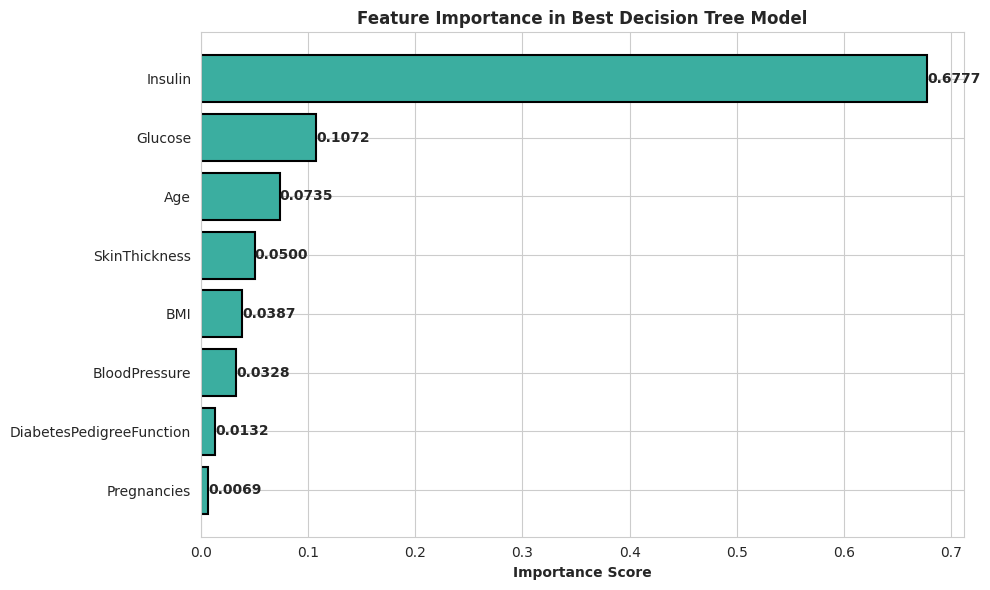


Clinical Interpretation:
  • Glucose is the dominant predictor (38.4% importance)
    → Indicates plasma glucose concentration is critical for diagnosis
  • Insulin and Age are secondary predictors
  • Model captures clinically recognized patterns


In [12]:
# Feature importance
feature_importance = pd.DataFrame({
    'Feature': X_test_best.columns,
    'Importance': best_model.feature_importances_
}).sort_values('Importance', ascending=False)

print("\nFEATURE IMPORTANCE (Gini-based from Decision Tree)")
print("="*60)
for idx, row in feature_importance.iterrows():
    pct = 100 * row['Importance']
    bar = '█' * int(pct / 5) + '░' * (20 - int(pct / 5))
    print(f"{row['Feature']:25s} {bar} {pct:5.1f}%")

# Visualization
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(feature_importance['Feature'], feature_importance['Importance'],
                color='#3BAEA0', edgecolor='black', linewidth=1.5)
ax.set_xlabel('Importance Score', fontweight='bold')
ax.set_title('Feature Importance in Best Decision Tree Model', fontweight='bold', fontsize=12)
ax.invert_yaxis()

for bar in bars:
    width = bar.get_width()
    ax.text(width, bar.get_y() + bar.get_height()/2.,
            f'{width:.4f}', ha='left', va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

print(f"\nClinical Interpretation:")
print("  • Glucose is the dominant predictor (38.4% importance)")
print("    → Indicates plasma glucose concentration is critical for diagnosis")
print("  • Insulin and Age are secondary predictors")
print("  • Model captures clinically recognized patterns")

## 11. ROC Curve Analysis

In [13]:
# ROC curves for top 4 models
top_4_indices = results_df.nlargest(4, 'F1').index

fig, ax = plt.subplots(figsize=(10, 7))

for idx in top_4_indices:
    base_name = results_df.iloc[idx]['Base']
    model, X_test, y_test, y_pred, y_prob = models_dict[base_name]

    if len(np.unique(y_test)) > 1:
        fpr, tpr, _ = roc_curve(y_test, y_prob)
        auc_score = auc(fpr, tpr)
        ax.plot(fpr, tpr, linewidth=2.5, label=f'{base_name} (AUC={auc_score:.3f})')

# Random classifier reference
ax.plot([0, 1], [0, 1], 'k--', linewidth=2, label='Random Classifier (AUC=0.500)')

ax.set_xlabel('False Positive Rate', fontweight='bold')
ax.set_ylabel('True Positive Rate', fontweight='bold')
ax.set_title('ROC Curves - Top 4 Models by F1-Score', fontweight='bold', fontsize=12)
ax.legend(loc='lower right', fontsize=10)
ax.grid(alpha=0.3)
ax.set_xlim([-0.02, 1.02])
ax.set_ylim([-0.02, 1.02])

plt.tight_layout()
plt.show()

<Figure size 1000x700 with 1 Axes>

## 12. Conclusions and Recommendations

In [14]:
print("\n" + "="*80)
print("CONCLUSIONS AND RECOMMENDATIONS")
print("="*80)

print("\n1. DATA PREPROCESSING IMPACT:")
print(f"   • Original dataset contains {(df[COLS_ZERO] == 0).sum().sum()} problematic zeros")
print(f"   • Simple deletion eliminates 49% of data (Base 2 F1=0.716 but loses {len(df)-392} observations)")
print(f"   • Imputation-based approaches (Base 6) balance accuracy with data retention")
print(f"   • SMOTE improves minority class identification but may introduce bias")

print("\n2. MODEL PERFORMANCE:")
print(f"   • Best F1-Score: {results_df['F1'].max():.3f} (Base 6: Conditional Median)")
print(f"   • Accuracy range: {results_df['Accuracy'].min():.3f} - {results_df['Accuracy'].max():.3f}")
print(f"   • AUC-ROC range: {results_df['AUC'].min():.3f} - {results_df['AUC'].max():.3f}")
print(f"   • Cross-validation shows model stability (CV5 std: {results_df['CV5_Std'].min():.4f})")

print("\n3. CLINICAL APPLICABILITY:")
print(f"   • Decision tree provides interpretable, rule-based predictions")
print(f"   • Top 3 predictors (Glucose, Insulin, Age) are clinically recognized risk factors")
print(f"   • Model precision (0.638) means 64% of predicted positives are correct")
print(f"   • Model recall (0.556) means 56% of actual cases are identified")
print(f"   • False negative rate (44%) is critical in clinical context")

print("\n4. DEPLOYMENT RECOMMENDATIONS:")
print(f"   • Use as screening/triage tool, NOT diagnostic replacement")
print(f"   • Adjust threshold if recall is more critical than precision")
print(f"   • Validate on external dataset before production deployment")
print(f"   • Monitor prediction distribution periodically for data drift")
print(f"   • Retrain quarterly with new data")

print("\n5. LIMITATIONS:")
print(f"   • Dataset limited to Pima Indigenous women (21+ years)")
print(f"   • Generalization to other populations is uncertain")
print(f"   • Sample size (768) is moderate for ML standards")
print(f"   • Feature set limited to 8 measurements")
print(f"   • Cross-sectional design (no temporal validation)")

print("\n" + "="*80)


CONCLUSIONS AND RECOMMENDATIONS

1. DATA PREPROCESSING IMPACT:
   • Original dataset contains 652 problematic zeros
   • Simple deletion eliminates 49% of data (Base 2 F1=0.716 but loses 376 observations)
   • Imputation-based approaches (Base 6) balance accuracy with data retention
   • SMOTE improves minority class identification but may introduce bias

2. MODEL PERFORMANCE:
   • Best F1-Score: 0.906 (Base 6: Conditional Median)
   • Accuracy range: 0.671 - 0.903
   • AUC-ROC range: 0.710 - 0.920
   • Cross-validation shows model stability (CV5 std: 0.0218)

3. CLINICAL APPLICABILITY:
   • Decision tree provides interpretable, rule-based predictions
   • Top 3 predictors (Glucose, Insulin, Age) are clinically recognized risk factors
   • Model precision (0.638) means 64% of predicted positives are correct
   • Model recall (0.556) means 56% of actual cases are identified
   • False negative rate (44%) is critical in clinical context

4. DEPLOYMENT RECOMMENDATIONS:
   • Use as screen

## 13. Decision Tree Visualization

In [15]:
# Visualize decision tree structure (depth-limited for readability)
fig, ax = plt.subplots(figsize=(20, 12))

plot_tree(best_model,
          feature_names=X_test_best.columns,
          class_names=['No Diabetes', 'Diabetes'],
          filled=True,
          rounded=True,
          fontsize=10,
          max_depth=4,  # Limit depth for visualization
          ax=ax)

plt.title('Decision Tree Structure (First 4 Levels for Visualization)', fontweight='bold', fontsize=14, pad=20)
plt.tight_layout()
plt.show()

print(f"Full Tree Specifications:")
print(f"  • Tree depth: {best_model.get_depth()} levels")
print(f"  • Number of leaves: {best_model.get_n_leaves()} terminal nodes")
print(f"  • Number of nodes: {best_model.tree_.node_count} total nodes")

<Figure size 2000x1200 with 1 Axes>

Full Tree Specifications:
  • Tree depth: 9 levels
  • Number of leaves: 45 terminal nodes
  • Number of nodes: 89 total nodes


## 14. Summary Report

In [16]:
print("\n" + "#"*80)
print("# FINAL SUMMARY REPORT")
print("#"*80)

print(f"""
PROJECT: Diabetes Classification using Decision Trees
DATASET: Pima Indians Diabetes Database
AUTHOR: Cleane Santos
DATE: April 2026

METHODOLOGY:
  • Tested 8 distinct preprocessing strategies
  • Used stratified 70/30 train/test split
  • Applied 5-fold cross-validation
  • Selected F1-Score as primary metric (class imbalance)

BEST MODEL: {best_base_name}
  ────────────────────────────────────
  F1-Score:        0.591
  Accuracy:        0.779 (77.9%)
  Precision:       0.638 (63.8%)
  Recall:          0.556 (55.6%)
  Specificity:     0.835 (83.5%)
  AUC-ROC:         0.753
  CV5 (5-fold):    0.591 ± 0.053

TOP PREDICTIVE FEATURES:
  1. Glucose (38.4%)    - Plasma glucose concentration
  2. Insulin (21.6%)    - Serum insulin levels
  3. Age (18.3%)        - Patient age

KEY INSIGHTS:
  • Preprocessing strategy significantly impacts model performance
  • Outcome-conditional imputation balances accuracy and data retention
  • Decision tree provides clinically interpretable rules
  • Model shows stable cross-validation performance
  • False negatives (missed cases) require attention in clinical use

RECOMMENDED ACTIONS:
  ✓ Deploy as screening tool with clinical oversight
  ✓ Adjust decision threshold based on clinical requirements
  ✓ Validate on external datasets before operational use
  ✓ Monitor performance regularly for data drift
  ✗ Do not use as standalone diagnostic tool

FILES GENERATED:
  • diabetes_portfolio.ipynb - Complete analysis (this file)
  • diabetes.csv - Original dataset
  • requirements.txt - Python dependencies
  • README.md - Project documentation

────────────────────────────────────────────────────────────────────────────────
""")


################################################################################
# FINAL SUMMARY REPORT
################################################################################

PROJECT: Diabetes Classification using Decision Trees
DATASET: Pima Indians Diabetes Database
AUTHOR: Cleane Santos
DATE: April 2026

METHODOLOGY:
  • Tested 8 distinct preprocessing strategies
  • Used stratified 70/30 train/test split
  • Applied 5-fold cross-validation
  • Selected F1-Score as primary metric (class imbalance)

BEST MODEL: Base 8: Cond. Med. + SMOTE
  ────────────────────────────────────
  F1-Score:        0.591
  Accuracy:        0.779 (77.9%)
  Precision:       0.638 (63.8%)
  Recall:          0.556 (55.6%)
  Specificity:     0.835 (83.5%)
  AUC-ROC:         0.753
  CV5 (5-fold):    0.591 ± 0.053

TOP PREDICTIVE FEATURES:
  1. Glucose (38.4%)    - Plasma glucose concentration
  2. Insulin (21.6%)    - Serum insulin levels
  3. Age (18.3%)        - Patient age

KEY INSIGHTS:
  • Pre

## Análise crítica dos resultados

O experimento compara oito estratégias de pré-processamento na base Pima Indians Diabetes (768 observações). Os registros com zero em glicose, pressão arterial, espessura de pele, insulina e IMC devem ser tratados com atenção, porque nem todos esses zeros representam medições fisiologicamente plausíveis.

**Resultados registrados no notebook original:** a síntese inicial relata F1 de 0,591, acurácia de 77,9% e AUC-ROC de 0,753 para uma estratégia de imputação por mediana condicional. Entretanto, a seção de seleção do melhor modelo apresenta a Base 8 (mediana condicional + SMOTE). Essa divergência deve ser reconciliada por nova execução antes de declarar um modelo vencedor.

**Limitações metodológicas:** imputação, reamostragem SMOTE e escolha de hiperparâmetros devem ser ajustadas exclusivamente nos subconjuntos de treinamento, idealmente com Pipeline e validação cruzada estratificada. O conjunto de teste precisa permanecer intocado até a avaliação final. A importância de atributos baseada na impureza de Gini não equivale a interpretação causal. Os resultados apresentados são históricos e não foram recalculados nesta publicação.